<a href="https://colab.research.google.com/github/tmachingur-code/EcoCycle-Hub/blob/main/EcoCycle_Hub_MobileNetV2_Cleaned.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EcoCycle Energy Hub : Plastic Material Classification

**Pipeline:** PET · HDPEM · OTHER  
**Model:** MobileNetV2 transfer learning  
**Dataset:** 4,819 validated images in Google Drive

This notebook is the cleaned classification workflow. It does not move, rename, delete, or overwrite source images. YOLO object detection will be added as a separate, verified stage after the classifier is evaluated.

## 1. Connect Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Configure paths, classes and reproducibility
The folder name below intentionally includes a space after `Backup` because that is how it appears in the current Google Drive path.

In [2]:
from pathlib import Path
import os
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

DATASET_PATH = Path(
    "/content/drive/MyDrive/EcoCycle_Hub/01_Original_Dataset_Backup /rawimgs"
)
MODEL_PATH = Path("/content/drive/MyDrive/EcoCycle_Hub/models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["PET", "HDPEM", "OTHER"]
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_PATH}")

print("Dataset:", DATASET_PATH)
print("Dataset folder exists:", DATASET_PATH.exists())
print("Classes:", CLASS_TO_INDEX)
print("Model output folder:", MODEL_PATH)

Dataset: /content/drive/MyDrive/EcoCycle_Hub/01_Original_Dataset_Backup /rawimgs
Dataset folder exists: True
Classes: {'PET': 0, 'HDPEM': 1, 'OTHER': 2}
Model output folder: /content/drive/MyDrive/EcoCycle_Hub/models


## 3. Validate dataset and count images
This cell checks image readability and reports counts. It does not modify the files.

In [ ]:
from PIL import Image

image_files_by_class = {}
dataset_summary = {}

for class_name in CLASS_NAMES:
    class_dir = DATASET_PATH / class_name
    if not class_dir.is_dir():
        raise FileNotFoundError(f"Missing class folder: {class_dir}")

    files = sorted(
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    valid_files = []
    corrupted_files = []

    for path in files:
        try:
            with Image.open(path) as image:
                image.verify()
            valid_files.append(path)
        except Exception:
            corrupted_files.append(path)

    image_files_by_class[class_name] = valid_files
    dataset_summary[class_name] = {
        "valid": len(valid_files),
        "corrupted": len(corrupted_files)
    }

    print(
        f"{class_name}: {len(valid_files)} valid, "
        f"{len(corrupted_files)} corrupted"
    )

total_valid = sum(len(files) for files in image_files_by_class.values())
print("-" * 45)
print("Total valid images:", total_valid)

if total_valid == 0:
    raise ValueError("No valid images were found.")
if any(dataset_summary[c]["valid"] == 0 for c in CLASS_NAMES):
    raise ValueError("At least one class has no valid images.")

PET: 1508 valid, 0 corrupted
HDPEM: 1028 valid, 0 corrupted
OTHER: 2283 valid, 0 corrupted
---------------------------------------------
Total valid images: 4819


## 4. Visualise sample images

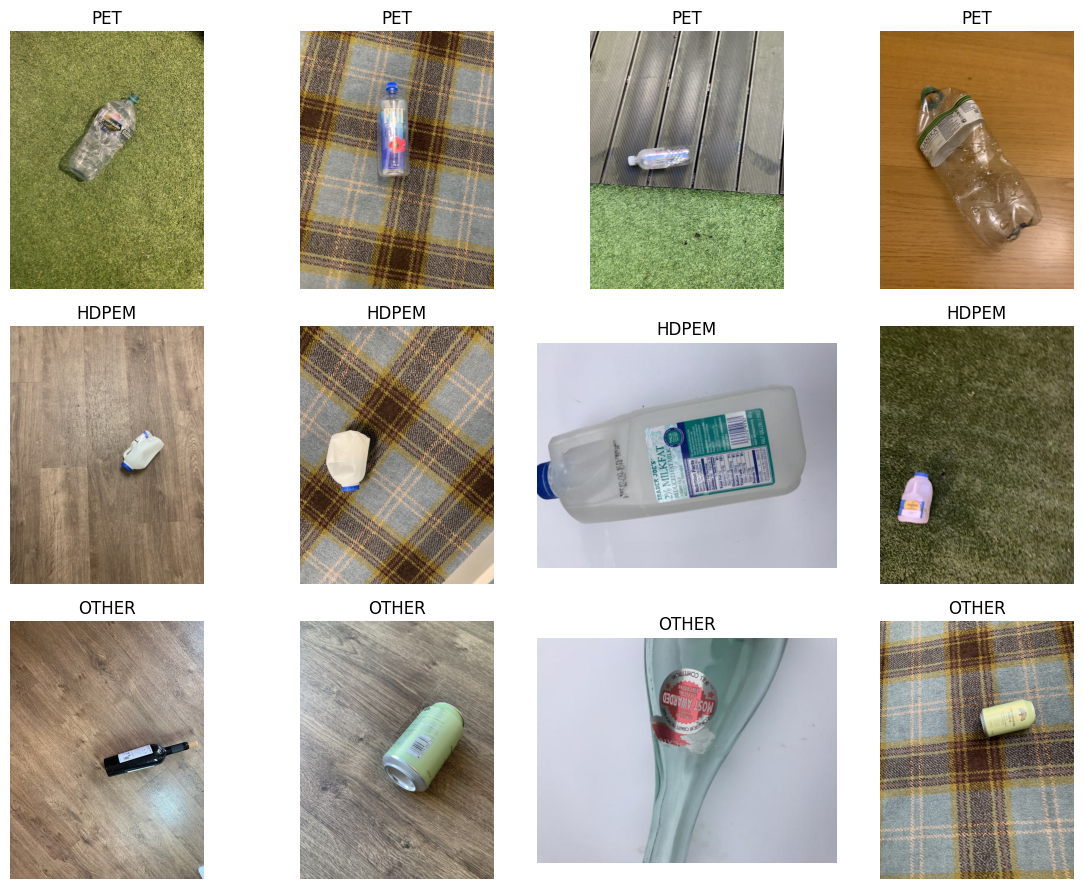

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(12, 9))

for row, class_name in enumerate(CLASS_NAMES):
    files = image_files_by_class[class_name]
    sample_count = min(4, len(files))
    samples = random.sample(files, sample_count)

    for col in range(4):
        axes[row, col].axis("off")
        if col < sample_count:
            with Image.open(samples[col]) as image:
                axes[row, col].imshow(image.convert("RGB"))
            axes[row, col].set_title(class_name)

plt.tight_layout()
plt.show()

## 5. Create stratified train, validation and test splits
The split is 70% training, 15% validation and 15% testing. Stratification preserves class proportions in each split.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

records = []
for class_name in CLASS_NAMES:
    for image_path in image_files_by_class[class_name]:
        records.append({
            "image_path": str(image_path),
            "label": class_name
        })

dataset = pd.DataFrame(records)

train_data, temporary_data = train_test_split(
    dataset,
    test_size=0.30,
    stratify=dataset["label"],
    random_state=SEED
)

validation_data, test_data = train_test_split(
    temporary_data,
    test_size=0.50,
    stratify=temporary_data["label"],
    random_state=SEED
)

for split_name, split_df in [
    ("Training", train_data),
    ("Validation", validation_data),
    ("Testing", test_data)
]:
    print(f"\n{split_name}: {len(split_df)} images")
    print(split_df["label"].value_counts().reindex(CLASS_NAMES, fill_value=0))

print("\nTotal assigned:", len(train_data) + len(validation_data) + len(test_data))
print("Original total:", len(dataset))


Training: 3373 images
label
PET      1055
HDPEM     720
OTHER    1598
Name: count, dtype: int64

Validation: 723 images
label
PET      227
HDPEM    154
OTHER    342
Name: count, dtype: int64

Testing: 723 images
label
PET      226
HDPEM    154
OTHER    343
Name: count, dtype: int64

Total assigned: 4819
Original total: 4819


## 6. Prepare TensorFlow datasets
MobileNetV2 preprocessing maps image pixels to the range expected by its pretrained feature extractor.

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

TensorFlow: 2.21.0
Image size: (224, 224)
Batch size: 32


In [ ]:
def load_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = preprocess_input(image)
    return image, label


def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].to_numpy()
    labels = dataframe["label"].map(CLASS_TO_INDEX).to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_dataset = create_dataset(train_data, training=True)
validation_dataset = create_dataset(validation_data)
test_dataset = create_dataset(test_data)

print("Training, validation and test datasets are ready.")

Training, validation and test datasets are ready.


## 7. Verify one batch

In [ ]:
images, labels = next(iter(train_dataset))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First five numeric labels:", labels[:5].numpy())
print("Class mapping:", CLASS_TO_INDEX)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First five numeric labels: [2 2 2 0 0]
Class mapping: {'PET': 0, 'HDPEM': 1, 'OTHER': 2}


## 8. Build the MobileNetV2 classifier
The pretrained ImageNet feature extractor is frozen for the initial training stage.

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(CLASS_NAMES), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 9. Configure class weights and training callbacks
Class weights compensate for the different number of images in each class.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

y_train = train_data["label"].map(CLASS_TO_INDEX).to_numpy()

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASS_NAMES)),
    y=y_train
)
class_weights = {index: float(weight) for index, weight in enumerate(weights)}

BEST_MODEL_FILE = MODEL_PATH / "best_ecocycle_3class_model.keras"

callbacks = [
    ModelCheckpoint(
        filepath=str(BEST_MODEL_FILE),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Class weights:", class_weights)
print("Best model will be saved to:", BEST_MODEL_FILE)

Class weights: {0: 1.0657187993680886, 1: 1.561574074074074, 2: 0.7035878181059658}
Best model will be saved to: /content/drive/MyDrive/EcoCycle_Hub/models/best_ecocycle_3class_model.keras


## 10. Train MobileNetV2
This is the main training cell. It may take several minutes depending on the Colab runtime.

In [ ]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6401 - loss: 0.7744
Epoch 1: val_loss improved from None to 0.31035, saving model to /content/drive/MyDrive/EcoCycle_Hub/models/best_ecocycle_3class_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EcoCycle_Hub/models/best_ecocycle_3class_model.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 242s 2s/step - accuracy: 0.7569 - loss: 0.5359 - val_accuracy: 0.8880 - val_loss: 0.3104 - learning_rate: 0.0010
Epoch 2/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8849 - loss: 0.2717
Epoch 2: val_loss improved from 0.31035 to 0.23229, saving model to /content/drive/MyDrive/EcoCycle_Hub/models/best_ecocycle_3class_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/EcoCycle_Hub/models/best_ecocycle_3class_model.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 238s 2s/step - accuracy: 0.8968 - loss: 0.2537 - val_accuracy: 0.9198 - val_loss: 0.2323 - learning_rate: 0.0010
Epoch 3/10
106/106 ━━━━━━━━━━━━━━━━━━━━

## 11. Plot training history

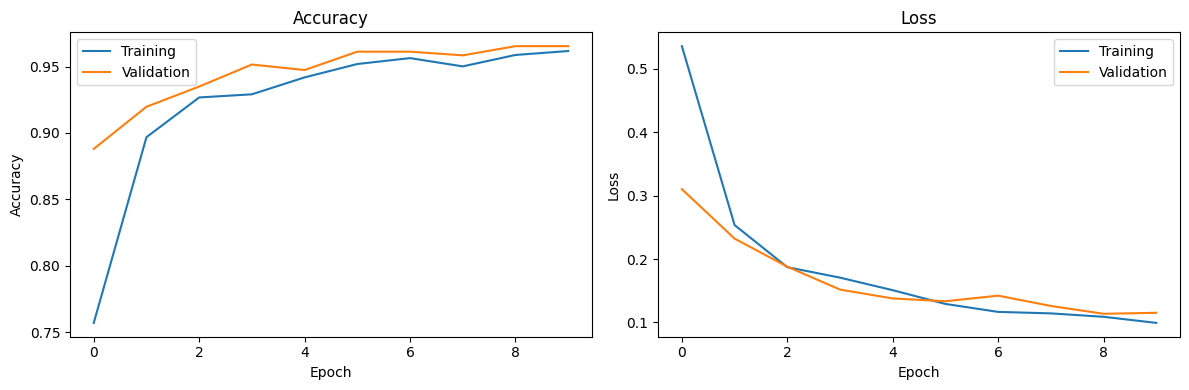

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## 12. Evaluate on the held-out test set
The test set is used only for final evaluation, not for model fitting.

In [ ]:
best_model = tf.keras.models.load_model(BEST_MODEL_FILE)

test_loss, test_accuracy = best_model.evaluate(test_dataset, verbose=1)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.9585 - loss: 0.1161
Test accuracy: 95.85%
Test loss: 0.1161


## 13. Classification report and confusion matrix

              precision    recall  f1-score   support

         PET       0.93      0.96      0.95       226
       HDPEM       0.99      0.98      0.98       154
       OTHER       0.96      0.95      0.96       343

    accuracy                           0.96       723
   macro avg       0.96      0.96      0.96       723
weighted avg       0.96      0.96      0.96       723



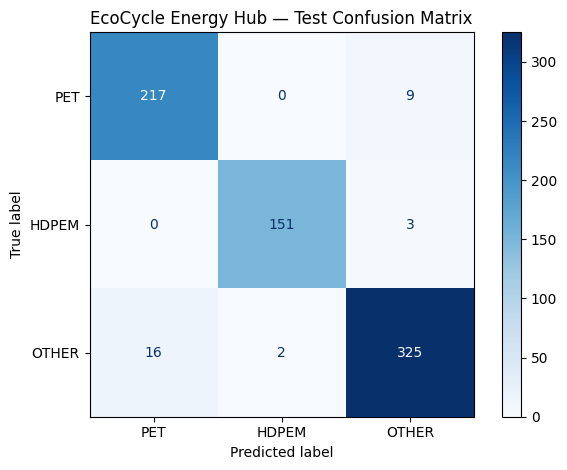

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true = np.concatenate([batch_labels.numpy() for _, batch_labels in test_dataset])
y_prob = best_model.predict(test_dataset, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES)))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
).plot(cmap="Blues", values_format="d")

plt.title("EcoCycle Energy Hub — Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 14. Review misclassified test images

Incorrect predictions: 30


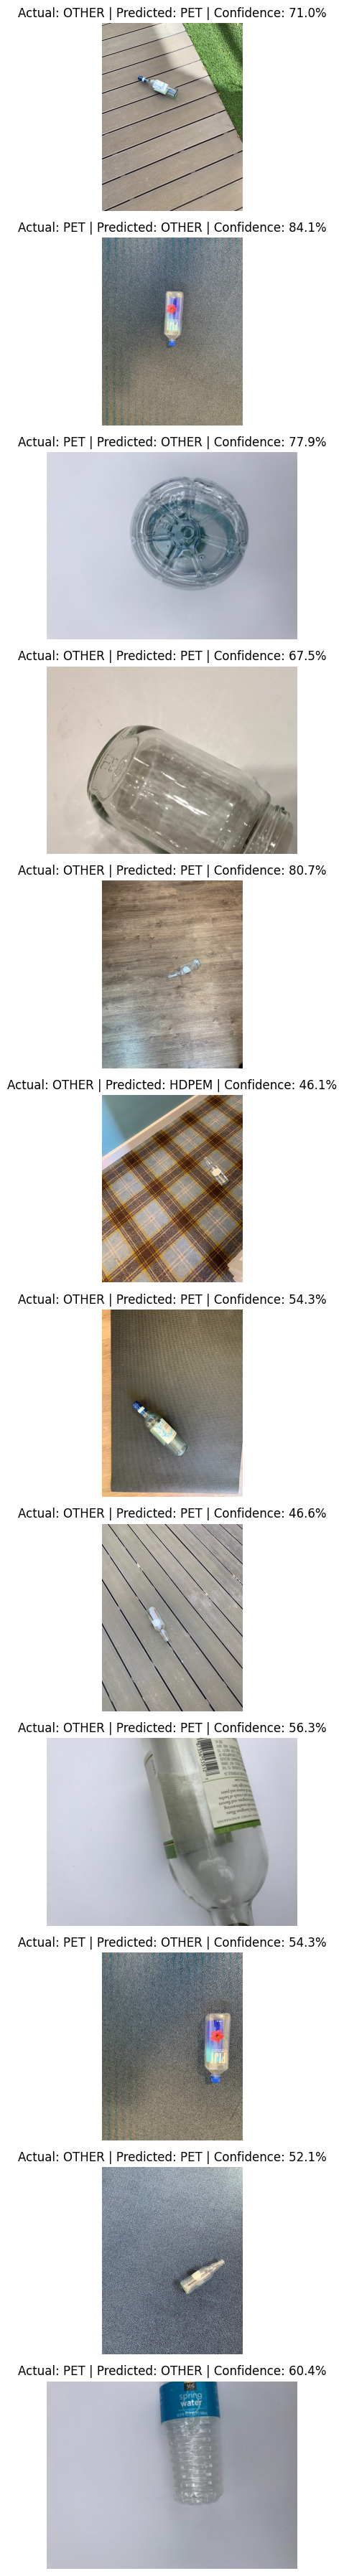

In [ ]:
misclassified = np.flatnonzero(y_true != y_pred)
print("Incorrect predictions:", len(misclassified))

show_indices = misclassified[:12]

if len(show_indices) == 0:
    print("No misclassified images in this test set.")
else:
    fig, axes = plt.subplots(
        len(show_indices), 1,
        figsize=(8, max(4, len(show_indices) * 3))
    )
    if len(show_indices) == 1:
        axes = [axes]

    for axis, index in zip(axes, show_indices):
        image_path = test_data.iloc[index]["image_path"]
        with Image.open(image_path) as image:
            axis.imshow(image.convert("RGB"))

        axis.set_title(
            f"Actual: {CLASS_NAMES[y_true[index]]} | "
            f"Predicted: {CLASS_NAMES[y_pred[index]]} | "
            f"Confidence: {y_prob[index].max():.1%}"
        )
        axis.axis("off")

    plt.tight_layout()
    plt.show()

## 15. Save and verify the final classifier

In [ ]:
# Save the best classifier in the project models folder.
best_model.save(BEST_MODEL_FILE)

print("Classifier saved:", BEST_MODEL_FILE)
print(f"File size: {BEST_MODEL_FILE.stat().st_size / (1024**2):.2f} MB")

Classifier saved: /content/drive/MyDrive/EcoCycle_Hub/models/best_ecocycle_3class_model.keras
File size: 9.21 MB


## 16. Next development stage — YOLO object detection

The MobileNetV2 classifier above assigns one material label to an image. It does not locate objects or produce bounding boxes.

The next stage is to prepare a verified YOLO detection dataset, train/evaluate an object detector, and then connect its detected crops to this classifier if the detector and class mapping are suitable.

**Do not run YOLO training from this notebook until the detection dataset's image-label pairs, annotation format, and class IDs have been verified.**

In [ ]:

from pathlib import Path
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EcoCycle_Hub/02_Additional_Datasets /SortWaste")

SOURCE = ROOT / "splited_all_dataset"
YOLO = ROOT / "splited_all_dataset_yolo"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Index every source image by filename
source_images = {}
for p in SOURCE.rglob("*"):
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
        source_images.setdefault(p.stem, []).append(p)

print("TOTAL SOURCE IMAGES:", sum(map(len, source_images.values())))
print("UNIQUE IMAGE FILENAMES:", len(source_images))

print("\n" + "=" * 65)
print("SPLIT-BY-SPLIT MATCHING")
print("=" * 65)

all_results = {}

for split in ["train", "val", "test"]:
    label_dir = YOLO / split / "labels"
    labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

    matched = []
    missing = []

    for label in labels:
        if label.stem in source_images:
            matched.append((label, source_images[label.stem]))
        else:
            missing.append(label)

    all_results[split] = {
        "labels": labels,
        "matched": matched,
        "missing": missing
    }

    print(f"\n{split.upper()}")
    print("-" * 45)
    print("Label files:", len(labels))
    print("Matched filenames:", len(matched))
    print("Labels without source images:", len(missing))

    if missing:
        print("Missing examples:", [p.name for p in missing[:10]])

    if matched:
        print("Matched examples:", [
            (label.name, [p.name for p in imgs])
            for label, imgs in matched[:3]
        ])

# Validate annotation contents
print("\n" + "=" * 65)
print("YOLO ANNOTATION VALIDATION")
print("=" * 65)

for split, result in all_results.items():
    invalid = 0
    class_counts = Counter()

    for label in result["labels"]:
        try:
            for line in label.read_text().splitlines():
                parts = line.strip().split()
                if not parts:
                    continue

                if len(parts) != 5:
                    invalid += 1
                    continue

                cls, x, y, w, h = map(float, parts)

                if (
                    not cls.is_integer()
                    or cls < 0 or cls >= 8
                    or not all(0 <= v <= 1 for v in [x, y, w, h])
                    or w <= 0 or h <= 0
                ):
                    invalid += 1
                else:
                    class_counts[int(cls)] += 1

        except Exception:
            invalid += 1

    print(f"\n{split.upper()}:")
    print("Invalid annotation lines/files:", invalid)
    print("Class distribution:", dict(sorted(class_counts.items())))

print("\nAUDIT COMPLETE — NO FILES MODIFIED")


TOTAL SOURCE IMAGES: 2257
UNIQUE IMAGE FILENAMES: 2257

SPLIT-BY-SPLIT MATCHING

TRAIN
---------------------------------------------
Label files: 3653
Matched filenames: 1425
Labels without source images: 2228
Missing examples: ['0019_1199_5.txt', '0019_1201_5.txt', '0019_1209_5.txt', '0019_0187_5.txt', '0019_0188_5.txt', '0019_1485_5.txt', '0019_1526_5.txt', '0019_1538_5.txt', '0019_1541_5.txt', '0019_1549_5.txt']
Matched examples: [('0008_2211_5.txt', ['0008_2211_5.png']), ('0008_2213_5.txt', ['0008_2213_5.png']), ('0008_2219_5.txt', ['0008_2219_5.png'])]

VAL
---------------------------------------------
Label files: 780
Matched filenames: 780
Labels without source images: 0
Matched examples: [('0019_0826_5.txt', ['0019_0826_5.png']), ('0019_0827_5.txt', ['0019_0827_5.png']), ('0019_0828_5.txt', ['0019_0828_5.png'])]

TEST
---------------------------------------------
Label files: 775
Matched filenames: 0
Labels without source images: 775
Missing examples: ['0019_0226_5.txt', '0019_

In [ ]:

from pathlib import Path
from PIL import Image
import shutil
import yaml

ROOT = Path("/content/drive/MyDrive/EcoCycle_Hub/02_Additional_Datasets /SortWaste")

SOURCE = ROOT / "splited_all_dataset"
LABEL_SOURCE = ROOT / "splited_all_dataset_yolo"

OUTPUT = ROOT / "ecocycle_yolo_clean"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

CLASS_NAMES = [
    "pet",
    "pead",
    "mixed_plastic_soft",
    "ecal",
    "metal",
    "cardboard",
    "mixed_plastic_rigid",
    "pet_oleo"
]

if OUTPUT.exists():
    print("Existing clean dataset found. Rebuilding it...")
    shutil.rmtree(OUTPUT)

OUTPUT.mkdir(parents=True)

summary = {}

for split in ["train", "val"]:
    image_dir = SOURCE / split / "images"
    label_dir = LABEL_SOURCE / split / "labels"

    out_images = OUTPUT / split / "images"
    out_labels = OUTPUT / split / "labels"

    out_images.mkdir(parents=True)
    out_labels.mkdir(parents=True)

    if not image_dir.exists() or not label_dir.exists():
        raise FileNotFoundError(f"Missing source folder for {split}")

    images_by_stem = {
        p.stem: p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    }

    labels_by_stem = {
        p.stem: p for p in label_dir.glob("*.txt")
    }

    matched = sorted(set(images_by_stem) & set(labels_by_stem))
    copied = 0
    bad_images = []
    bad_labels = []

    for stem in matched:
        image_path = images_by_stem[stem]
        label_path = labels_by_stem[stem]

        try:
            with Image.open(image_path) as im:
                im.verify()
        except Exception:
            bad_images.append(image_path.name)
            continue

        # Validate every annotation line
        valid = True
        for line in label_path.read_text().splitlines():
            if not line.strip():
                continue

            parts = line.split()
            try:
                if len(parts) != 5:
                    valid = False
                    break

                cls, x, y, w, h = map(float, parts)

                if (
                    not cls.is_integer()
                    or not 0 <= cls < len(CLASS_NAMES)
                    or not all(0 <= v <= 1 for v in [x, y, w, h])
                    or w <= 0 or h <= 0
                ):
                    valid = False
                    break
            except Exception:
                valid = False
                break

        if not valid:
            bad_labels.append(label_path.name)
            continue

        shutil.copy2(image_path, out_images / image_path.name)
        shutil.copy2(label_path, out_labels / label_path.name)
        copied += 1

    summary[split] = copied

    print(f"\n{split.upper()}")
    print("Matching pairs:", len(matched))
    print("Successfully copied:", copied)
    print("Bad images:", len(bad_images))
    print("Bad annotations:", len(bad_labels))

    if bad_images:
        print("Bad image examples:", bad_images[:5])
    if bad_labels:
        print("Bad label examples:", bad_labels[:5])

# Generate YOLO configuration
data_config = {
    "path": str(OUTPUT),
    "train": "train/images",
    "val": "val/images",
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES
}

yaml_path = OUTPUT / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("\n" + "=" * 55)
print("CLEAN DATASET CREATED")
print("=" * 55)
print("Location:", OUTPUT)
print("Training pairs:", summary["train"])
print("Validation pairs:", summary["val"])
print("Total pairs:", sum(summary.values()))
print("Configuration:", yaml_path)
print("\nOriginal dataset was not modified.")
